In [1]:
import kagglehub
path = kagglehub.dataset_download("marcpaulo/titanic-huge-dataset-1m-passengers")

Using Colab cache for faster access to the 'titanic-huge-dataset-1m-passengers' dataset.


In [2]:
import os
os.listdir(path)

['huge_1M_titanic.csv']

In [3]:
import pandas as pd
df=pd.read_csv(path+'/huge_1M_titanic.csv')

In [4]:
df.shape

(1000000, 12)

In [5]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1310,1,1,"Name1310, Miss. Surname1310",female,NaN,0,0,SOTON/O2 3101272,76.760165,NaN,C
1,1311,0,3,"Name1311, Col. Surname1311",male,29.0,0,0,223596,10.193097,NaN,S
2,1312,0,3,"Name1312, Mr. Surname1312",male,20.0,0,0,54636,12.029416,C83,C
3,1313,0,3,"Name1313, Mr. Surname1313",male,27.0,0,0,PC 17760,13.429448,NaN,S
4,1314,0,3,"Name1314, Mr. Surname1314",male,32.0,0,0,364512,4.840769,E33,C


In [6]:
df['Members']=df['SibSp']+df['Parch']+1

In [7]:
df.drop(columns=['Parch','SibSp'],inplace=True)

In [8]:
df['Fare_per_head']=df['Fare']/df['Members']

In [9]:
df[df['Fare_per_head']!=df['Fare']]

,PassengerId,Survived,Pclass,Name,Sex,Age,Ticket,Fare,Cabin,Embarked,Members,Fare_per_head
7,1317,1,2,"Name1317, Miss. Surname1317",female,28.0,113781,27.950048,NaN,S,2,13.975024
10,1320,1,3,"Name1320, Miss. Surname1320",female,23.0,7534,20.822546,NaN,S,2,10.411273
12,1322,1,3,"Name1322, Miss. Surname1322",female,NaN,S.O./P.P. 3,12.462809,NaN,S,2,6.231405
17,1327,1,2,"Name1327, Master. Surname1327",female,4.0,A/5. 10482,26.712402,NaN,S,3,8.904134
19,1329,0,3,"Name1329, Mr. Surname1329",male,NaN,315082,20.566141,NaN,S,3,6.855380
...,...,...,...,...,...,...,...,...,...,...,...,...
999989,1001299,0,1,"Name1001299, Mr. Surname1001299",male,NaN,350047,65.639884,NaN,S,2,32.819942
999990,1001300,1,3,"Name1001300, Master. Surname1001300",female,7.0,330931,2.725446,NaN,S,3,0.908482
999991,1001301,0,2,"Name1001301, Mr. Surname1001301",male,39.0,113501,14.754439,NaN,S,2,7.377220
999997,1001307,0,3,"Name1001307, Mr. Surname1001307",male,NaN,PC 17601,8.274807,NaN,S,2,4.137404


In [10]:
df['Cabin'].isnull().sum()

np.int64(770195)

##Since we have a lots of nulls in Cabin block so we can just remove it.

In [11]:
df.drop(columns=['PassengerId','Name','Ticket','Cabin','Fare_per_head'],inplace=True)

In [12]:
df.head(3)

,Survived,Pclass,Sex,Age,Fare,Embarked,Members
0,1,1,female,NaN,76.760165,C,1
1,0,3,male,29.0,10.193097,S,1
2,0,3,male,20.0,12.029416,C,1


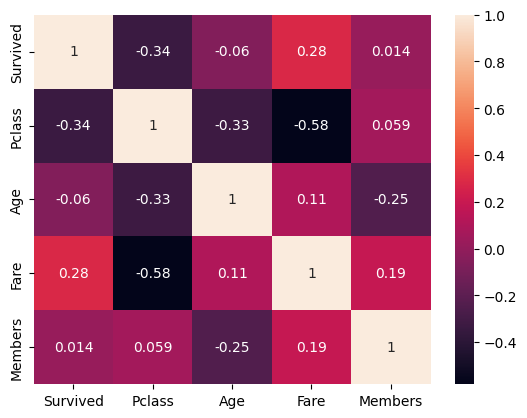

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
corr=df.corr(numeric_only=True)
sns.heatmap(corr,annot=True)
plt.show()

In [14]:
print(f'Column {'Age'} has {df['Age'].isnull().sum()} : {df['Age'].isnull().mean()*100:.4f}% missing values')
print(f'Column {'Pclass'} has {df['Pclass'].isnull().sum()} : {df['Pclass'].isnull().mean()*100:.4f}% missing values')

Column Age has 198600 : 19.8600% missing values
Column Pclass has 0 : 0.0000% missing values


## Since Age column is negatively correlated to Survived or dependent column and about 20% of the datapoints are missing so we can dimply remove the Age Column.
## We can keep Pclass Column as it has no missing values and we can use it to classify as categories rich,medium or poor class.

In [15]:
df.drop(columns=['Age'],inplace=True)

In [16]:
df.shape

(1000000, 6)

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 6 columns):
 #   Column    Non-Null Count    Dtype  
---  ------    --------------    -----  
 0   Survived  1000000 non-null  int64  
 1   Pclass    1000000 non-null  int64  
 2   Sex       1000000 non-null  object 
 3   Fare      1000000 non-null  float64
 4   Embarked  997760 non-null   object 
 5   Members   1000000 non-null  int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 45.8+ MB


In [18]:
df['Pclass']=df['Pclass'].astype('int32')
df['Fare']=df['Fare'].astype('float32')
df['Members']=df['Members'].astype('int32')

In [19]:
df.isnull().sum()

,0
Survived,0
Pclass,0
Sex,0
Fare,0
Embarked,2240
Members,0


In [20]:
df['Embarked'].value_counts()

,count
Embarked,
S,729468
C,186846
Q,81446


## People started their journey from mainly 3 stations:
## C: Cherbourg
## Q: Queenstown
## S: Southampton
## Most of the people started their jouney from Southampton.

In [21]:
for i in df.columns:
  print(f'Column {i} has {df[i].isnull().sum()} : {df[i].isnull().mean()*100:.4f}% missing values')

Column Survived has 0 : 0.0000% missing values
Column Pclass has 0 : 0.0000% missing values
Column Sex has 0 : 0.0000% missing values
Column Fare has 0 : 0.0000% missing values
Column Embarked has 2240 : 0.2240% missing values
Column Members has 0 : 0.0000% missing values


In [22]:
df=df[df['Embarked'].isnull()!=True]

In [23]:
def update(value):
  if value=='C':
    return "Cherbourg"
  elif value=='Q':
    return "Queenstown"
  else:
    return "Southampton"
df['Embarked']=df['Embarked'].apply(update)

In [24]:
df.duplicated().sum()

np.int64(62552)

In [25]:
df.drop_duplicates(inplace=True)

In [26]:
df.describe()

,Survived,Pclass,Fare,Members
count,935208.000000,935208.000000,935208.000000,935208.000000
mean,0.383330,2.324787,35.681297,1.910549
std,0.486198,0.831013,48.742531,1.638624
min,0.000000,1.000000,0.000000,1.000000
25%,0.000000,2.000000,9.819324,1.000000
50%,0.000000,3.000000,17.172701,1.000000
75%,1.000000,3.000000,38.051301,2.000000
max,1.000000,3.000000,640.883606,11.000000


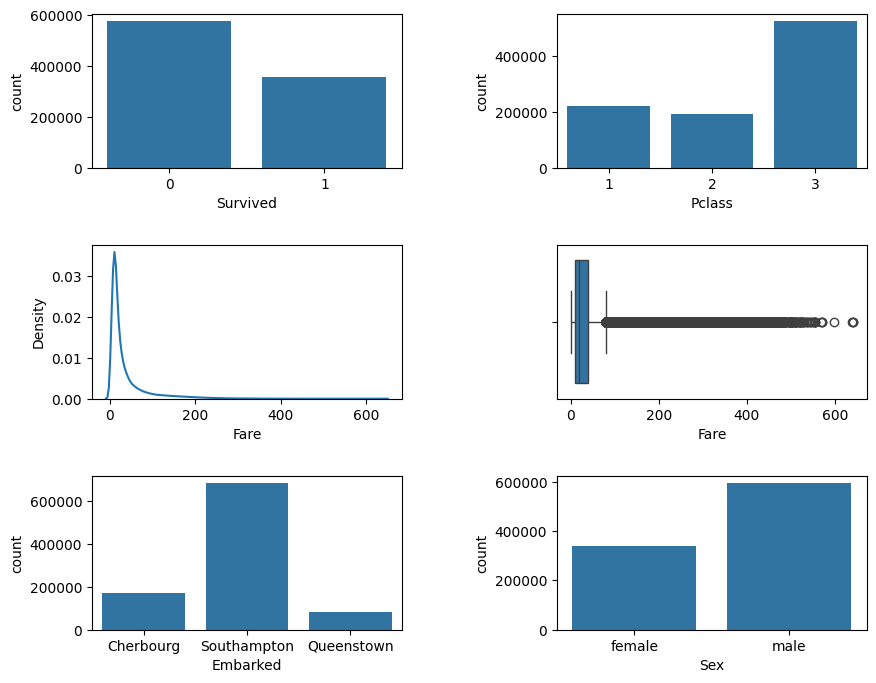

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
fig,ax=plt.subplots(3,2,figsize=(10,8))
sns.countplot(df,x='Survived',ax=ax[0,0])
sns.countplot(df,x='Pclass',ax=ax[0,1])
sns.kdeplot(df,x='Fare',ax=ax[1,0])
sns.boxplot(df,x='Fare',ax=ax[1,1])
sns.countplot(df,x='Embarked',ax=ax[2,0])
sns.countplot(df,x='Sex',ax=ax[2,1])
plt.subplots_adjust(hspace=0.5,wspace=0.5)
plt.show()

In [28]:
df[(df['Fare']>500) & (df['Members']==1)]

,Survived,Pclass,Sex,Fare,Embarked,Members
93188,1,1,female,639.557373,Cherbourg,1
117380,1,1,female,501.413544,Cherbourg,1
179305,1,1,female,528.534790,Cherbourg,1
215778,1,1,female,640.251892,Cherbourg,1
639823,1,1,male,541.470520,Cherbourg,1
752621,1,1,female,528.391174,Cherbourg,1


## As wealthy can pay more amount and there is not a single fellow so we may not consider as an outlier

In [29]:
df['Fare']=df['Fare'].apply(lambda x: f"{x:.2f}")

In [30]:
df.sample(4)

,Survived,Pclass,Sex,Fare,Embarked,Members
384939,1,2,female,50.70,Southampton,5
827981,1,1,female,75.47,Cherbourg,1
817454,0,3,male,9.15,Queenstown,1
578697,0,3,male,54.91,Southampton,8


In [31]:
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
le=LabelEncoder()
df['Sex']=le.fit_transform(df[['Sex']])

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [32]:
ohe=OneHotEncoder(sparse_output=False)
Embarked=ohe.fit_transform(df[['Embarked']])

In [33]:
names=ohe.get_feature_names_out()

In [34]:
Embarked=pd.DataFrame(Embarked,columns=names)

In [35]:
df.reset_index(drop=True,inplace=True)

In [36]:
df=pd.concat([df,Embarked],axis=1)

In [37]:
df.drop(columns=['Embarked'],inplace=True)

In [38]:
df.head()

,Survived,Pclass,Sex,Fare,Members,Embarked_Cherbourg,Embarked_Queenstown,Embarked_Southampton
0,1,1,0,76.76,1,1.0,0.0,0.0
1,0,3,1,10.19,1,0.0,0.0,1.0
2,0,3,1,12.03,1,1.0,0.0,0.0
3,0,3,1,13.43,1,0.0,0.0,1.0
4,0,3,1,4.84,1,1.0,0.0,0.0


In [39]:
df[['Embarked_Cherbourg','Embarked_Queenstown','Embarked_Southampton']]=df[['Embarked_Cherbourg','Embarked_Queenstown','Embarked_Southampton']].astype('int32')

In [40]:
import joblib
with open('onehotencoder.pkl','wb') as f:
  joblib.dump(ohe,f)
with open('labelencoder.pkl','wb') as f:
  joblib.dump(le,f)

In [41]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
df[['Pclass','Sex','Fare','Members']]=scaler.fit_transform(df[['Pclass','Sex','Fare','Members']])

In [42]:
df.head()

,Survived,Pclass,Sex,Fare,Members,Embarked_Cherbourg,Embarked_Queenstown,Embarked_Southampton
0,1,-1.594184,-1.325118,0.842620,-0.555679,1,0,0
1,0,0.812519,0.754650,-0.522886,-0.555679,0,0,1
2,0,0.812519,0.754650,-0.485143,-0.555679,1,0,0
3,0,0.812519,0.754650,-0.456426,-0.555679,0,0,1
4,0,0.812519,0.754650,-0.632627,-0.555679,1,0,0


In [43]:
with open('scaler.pkl','wb') as f:
  joblib.dump(scaler,f)

In [44]:
x=df.drop(columns=['Survived'])
y=df['Survived']

In [45]:
x.shape,y.shape

((935208, 7), (935208,))

In [46]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [47]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((748166, 7), (187042, 7), (748166,), (187042,))

In [48]:
x_train,x_valid,y_train,y_valid=train_test_split(x_train,y_train,test_size=0.2,random_state=42)

In [49]:
x_train.shape,x_valid.shape,y_train.shape,y_valid.shape

((598532, 7), (149634, 7), (598532,), (149634,))

In [50]:
import tensorflow

In [51]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping

In [52]:
(x_train.shape[1],)

(7,)

In [53]:
model=Sequential([Dense(64,input_shape=(x_train.shape[1],),activation='relu'),            # First Hidden Layer
            Dense(32,activation='relu'),                                                  # Second Hidden Layer
            Dense(1,activation='sigmoid')                                                 # Output Layer
            ])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [54]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,625 (10.25 KB)

 Trainable params: 2,625 (10.25 KB)

 Non-trainable params: 0 (0.00 B)

## Dense Layer is Hidden Layer 1 : Total parameters=512 means  (7*64 weights +64 bias associated with hidden layer 1)
## Dense Layer_1 has 2080 param as (64*32 weights +32 bias associated with hidden layer 2)
## Dense Layer_2 has 2080 param as (32*1 weights +1 bias associated with output layer)

In [55]:
opt=tensorflow.keras.optimizers.Adam(learning_rate=0.01)

In [56]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [57]:
stopping_callback=EarlyStopping(patience=5,restore_best_weights=True)

In [58]:
model.fit(x_train,y_train,epochs=14,callbacks=stopping_callback,validation_data=(x_valid,y_valid))

Epoch 1/14
18705/18705 ━━━━━━━━━━━━━━━━━━━━ 49s 3ms/step - accuracy: 0.8461 - loss: 0.3434 - val_accuracy: 0.8499 - val_loss: 0.3352
Epoch 2/14
18705/18705 ━━━━━━━━━━━━━━━━━━━━ 53s 3ms/step - accuracy: 0.8536 - loss: 0.3292 - val_accuracy: 0.8556 - val_loss: 0.3276
Epoch 3/14
18705/18705 ━━━━━━━━━━━━━━━━━━━━ 48s 3ms/step - accuracy: 0.8562 - loss: 0.3250 - val_accuracy: 0.8569 - val_loss: 0.3221
Epoch 4/14
18705/18705 ━━━━━━━━━━━━━━━━━━━━ 46s 2ms/step - accuracy: 0.8574 - loss: 0.3233 - val_accuracy: 0.8568 - val_loss: 0.3223
Epoch 5/14
18705/18705 ━━━━━━━━━━━━━━━━━━━━ 46s 2ms/step - accuracy: 0.8575 - loss: 0.3222 - val_accuracy: 0.8573 - val_loss: 0.3218
Epoch 6/14
18705/18705 ━━━━━━━━━━━━━━━━━━━━ 47s 2ms/step - accuracy: 0.8579 - loss: 0.3215 - val_accuracy: 0.8571 - val_loss: 0.3219
Epoch 7/14
18705/18705 ━━━━━━━━━━━━━━━━━━━━ 45s 2ms/step - accuracy: 0.8582 - loss: 0.3210 - val_accuracy: 0.8575 - val_loss: 0.3215
Epoch 8/14
18705/18705 ━━━━━━━━━━━━━━━━━━━━ 45s 2ms/step - accuracy: 

In [59]:
model.save('model.h5')

In [75]:
model.evaluate(x_test,y_test)

5846/5846 ━━━━━━━━━━━━━━━━━━━━ 14s 2ms/step - accuracy: 0.8592 - loss: 0.3189


[0.3189190626144409, 0.8592241406440735]

In [77]:
pred=model.predict(x_test)

5846/5846 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step


In [80]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test,pred.round())

array([[105828,   9843],
       [ 16488,  54883]])